# Exponential Random Graph Models (ERGM)
## Example: *Grey's Anatomy* Social Network

**Data Source:** Garry Weissman, 2011  
**Adapted from:** Ian McCulloh, Ph.D.  

---

This notebook demonstrates how to fit **Exponential Random Graph Models (ERGMs)** using the `statnet` suite in R.

We will:
- Create a simple 3-node network
- Load real-world data from *Grey's Anatomy*
- Visualize the network with attributes
- Fit increasingly complex ERGMs

> **Required files in same directory:**
> - `gray-adj.csv` (adjacency matrix)
> - `gray-attr.csv` (node attributes)


## 1. Load Required Library

In [9]:
# Install statnet if needed (uncomment once)
install.packages("statnet")
library(statnet)
cat("statnet loaded successfully!\n")

Warning message:
"package 'statnet' is in use and will not be installed"


statnet loaded successfully!


## 2. Simple 3-Node Network Example

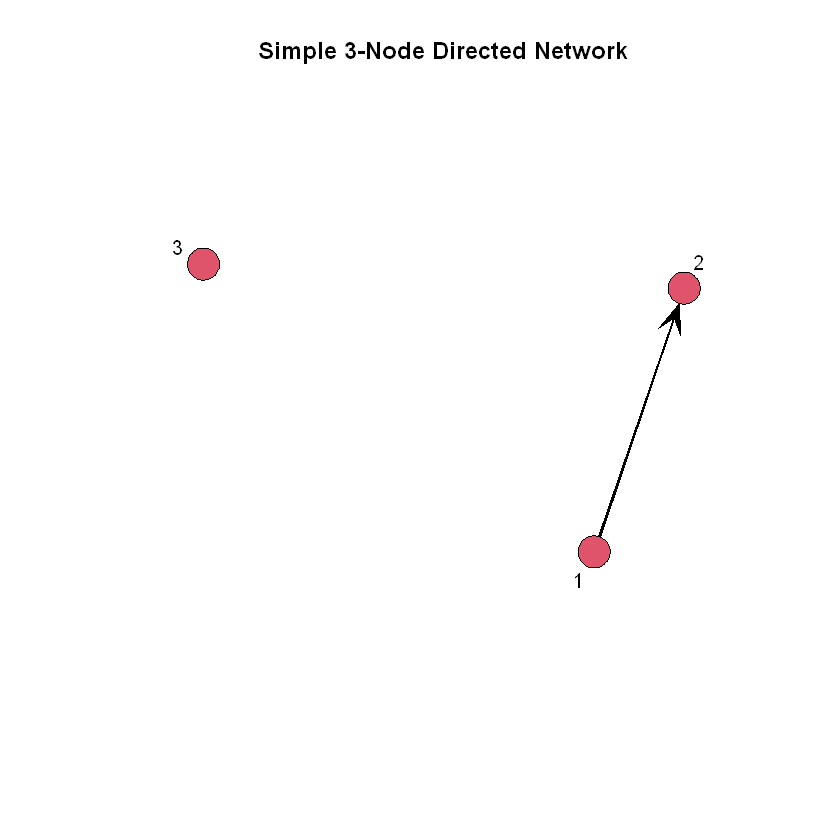

In [10]:
# Initialize a directed empty network with 3 nodes
n <- network.initialize(3, directed = TRUE)

# Add one directed edge: 1 → 2
n[1, 2] <- 1

# Plot the network
gplot(n, main = "Simple 3-Node Directed Network", displaylabels = TRUE)

In [11]:
# Fit ERGM with only edges term
e1 <- ergm(n ~ edges)
summary(e1)

Starting maximum pseudolikelihood estimation (MPLE):

Obtaining the responsible dyads.

Evaluating the predictor and response matrix.

Maximizing the pseudolikelihood.

Finished MPLE.

Evaluating log-likelihood at the estimate. 




Call:
ergm(formula = n ~ edges)

Maximum Likelihood Results:

      Estimate Std. Error MCMC % z value Pr(>|z|)
edges   -1.609      1.095      0  -1.469    0.142

     Null Deviance: 8.318  on 6  degrees of freedom
 Residual Deviance: 5.407  on 5  degrees of freedom
 
AIC: 7.407  BIC: 7.198  (Smaller is better. MC Std. Err. = 0)

> **Interpretation**: The coefficient for `edges` is the log-odds of a tie for each possible dyad, holding all else constant.

## 3. Load *Grey's Anatomy* Data

In [12]:
# Read adjacency matrix
ga.matrix <- as.matrix(read.table(
  "gray-adj.csv",
  sep = ",",
  header = TRUE,
  row.names = 1,
  quote = "\""
))

# Read node attributes
ga.attr <- read.csv(
  "gray-attr.csv",
  header = TRUE,
  sep = ",",
  stringsAsFactors = FALSE
)

cat("Adjacency matrix dimensions:", dim(ga.matrix), "\n")
cat("Number of attributes:", nrow(ga.attr), "\n")
head(ga.attr)

Adjacency matrix dimensions: 44 44 
Number of attributes: 44 


,name,sex,race,birthyear,position,season,sign
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>
1,addison,F,White,1967,Attending,1,Libra
2,adele,F,Black,1949,Non-Staff,2,Leo
3,altman,F,White,1969,Attending,6,Pisces
4,amelia,F,White,1981,Attending,7,Libra
5,arizona,F,White,1976,Attending,5,Leo
6,ava,F,White,1975,Non-Staff,3,Gemini


## 4. Create Network Object

In [13]:
# Create statnet network object
ga.net <- network(
  ga.matrix,
  vertex.attr = ga.attr,
  vertex.attrnames = colnames(ga.attr),
  directed = FALSE,
  loops = FALSE,
  multiple = FALSE,
  bipartite = FALSE
)

summary(ga.net)

Network attributes:
  vertices = 44
  directed = FALSE
  hyper = FALSE
  loops = FALSE
  multiple = FALSE
  bipartite = FALSE
 total edges = 49 
   missing edges = 0 
   non-missing edges = 49 
 density = 0.05179704 

Vertex attributes:

 birthyear:
   integer valued attribute
   44 values

 name:
   character valued attribute
   attribute summary:
   the 10 most common values are:
addison   adele  altman  amelia arizona     ava   avery  bailey     ben  burton 
      1       1       1       1       1       1       1       1       1       1 

 position:
   character valued attribute
   attribute summary:
Attending     Chief    Intern Non-Staff     Nurse     Other  Resident 
       14         2         3        12         2         2         9 

 race:
   character valued attribute
   attribute summary:
Black Other White 
    8     4    32 

 season:
   integer valued attribute
   44 values

 sex:
   character valued attribute
   attribute summary:
 F  M 
23 21 

 sign:
   character valu

## 5. Visualize the Network

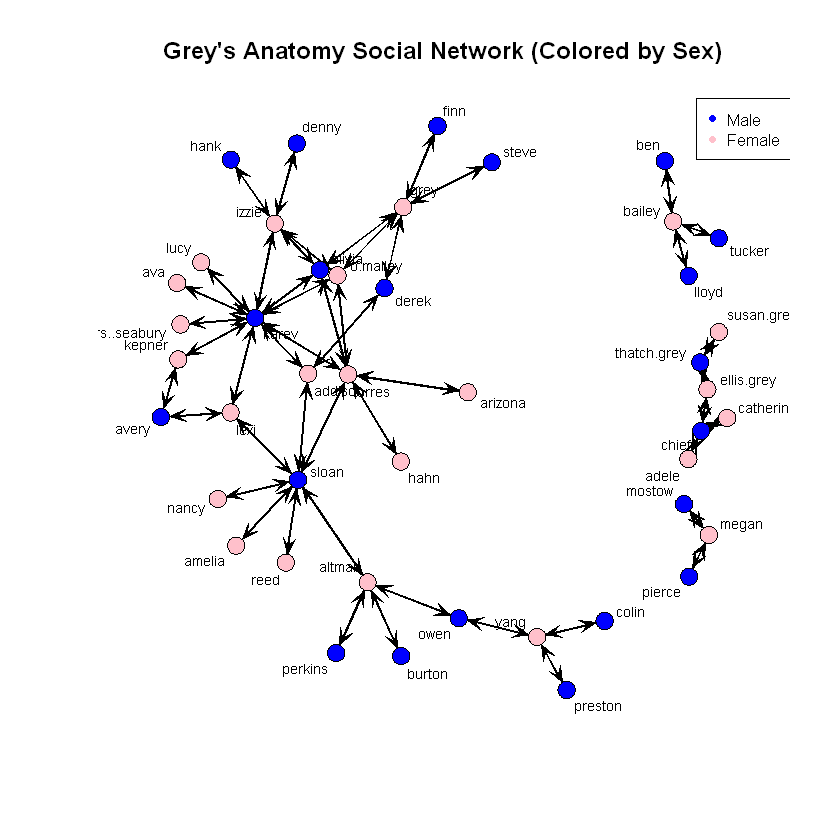

In [14]:
# Plot network colored by sex
sex_col <- c("blue", "pink")[1 + (get.vertex.attribute(ga.net, "sex") == "F")]

gplot(
  ga.net,
  vertex.col = sex_col,
  label = get.vertex.attribute(ga.net, "vertex.names"),
  label.cex = 0.7,
  main = "Grey's Anatomy Social Network (Colored by Sex)"
)

# Add legend
legend("topright", legend = c("Male", "Female"), col = c("blue", "pink"), pch = 19, cex = 0.8)

## 6. Fit ERGM Models

### Model 1: Edges Only (Baseline)

In [15]:
e2 <- ergm(ga.net ~ edges,
control = control.ergm(
  MCMC.samplesize = 10000,
  MCMC.interval = 5000,
  MCMC.burnin = 50000,
  seed = 631
))
summary(e2)

Starting maximum pseudolikelihood estimation (MPLE):

Obtaining the responsible dyads.

Evaluating the predictor and response matrix.

Maximizing the pseudolikelihood.

Finished MPLE.

Evaluating log-likelihood at the estimate. 




Call:
ergm(formula = ga.net ~ edges, control = control.ergm(MCMC.samplesize = 10000, 
    MCMC.interval = 5000, MCMC.burnin = 50000, seed = 631))

Maximum Likelihood Results:

      Estimate Std. Error MCMC % z value Pr(>|z|)    
edges  -2.9072     0.1467      0  -19.82   <1e-04 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

     Null Deviance: 1311.4  on 946  degrees of freedom
 Residual Deviance:  385.5  on 945  degrees of freedom
 
AIC: 387.5  BIC: 392.4  (Smaller is better. MC Std. Err. = 0)

### Model 2: Add Triadic Closure

In [16]:
# Model 2: Add transitivity with GWESP (geometrically weighted edgewise shared partners). May want to avoid triangles as they tend to be degenrate.
e3 <- ergm(ga.net ~ edges + gwesp(decay=0.7,fixed = TRUE),
           control = control.ergm(MCMC.samplesize = 5000,
                                  MCMC.interval = 2000,
                                  seed = 631))
summary(e3)

Starting maximum pseudolikelihood estimation (MPLE):

Obtaining the responsible dyads.

Evaluating the predictor and response matrix.

Maximizing the pseudolikelihood.

Finished MPLE.

Starting Monte Carlo maximum likelihood estimation (MCMLE):

Iteration 1 of at most 60:

Sampling ■■■■■■■■■                         26% |  ETA:  3s
Sampling ■■■■■■■■■■                        31% |  ETA:  3s
Sampling ■■■■■■■■■■■■                      36% |  ETA:  3s
Sampling ■■■■■■■■■■■■■                     41% |  ETA:  2s
Sampling ■■■■■■■■■■■■■■■                   46% |  ETA:  2s
Sampling ■■■■■■■■■■■■■■■■                  51% |  ETA:  2s
Sampling ■■■■■■■■■■■■■■■■■■                56% |  ETA:  2s
Sampling ■■■■■■■■■■■■■■■■■■■               60% |  ETA:  2s
Sampling ■■■■■■■■■■■■■■■■■■■■              65% |  ETA:  1s
Sampling ■■■■■■■■■■■■■■■■■■■■■■            70% |  ETA:  1s
Sampling ■■■■■■■■■■■■■■■■■■■■■■■           75% |  ETA:  1s
Sampling ■■■■■■■■■■■■■■■■■■■■■■■■■         80% |  ETA:  1s
Sampling ■■■■■■■■■

Call:
ergm(formula = ga.net ~ edges + gwesp(decay = 0.7, fixed = TRUE), 
    control = control.ergm(MCMC.samplesize = 5000, MCMC.interval = 2000, 
        seed = 631))

Monte Carlo Maximum Likelihood Results:

                Estimate Std. Error MCMC % z value Pr(>|z|)    
edges            -3.0146     0.1775      0 -16.983   <1e-04 ***
gwesp.fixed.0.7   0.2463     0.1890      0   1.303    0.192    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

     Null Deviance: 1311.4  on 946  degrees of freedom
 Residual Deviance:  384.3  on 944  degrees of freedom
 
AIC: 388.3  BIC: 398  (Smaller is better. MC Std. Err. = 0.01337)

> Positive `triangle` coefficient → tendency toward **transitive closure** (friends of friends become friends).

### Model 3: Add Gender Homophily

In [ ]:
e4 <- ergm(ga.net ~ edges + gwesp(decay=0.7,fixed = TRUE) + nodematch("sex"),
           control = control.ergm(MCMC.samplesize = 5000,
                                  MCMC.interval = 2000,
                                  seed = 631) )
summary(e4)

> `nodematch("sex")` > 0 → **homophily**: people of same sex are more likely to be connected.

### Model 4: Test Racial Homophily

In [ ]:
e5 <- ergm(ga.net ~ edges + nodematch("race"))
summary(e5)

> Compare coefficient magnitude and significance with gender homophily.

## 7. Model Comparison Table

In [ ]:
model_comparison <- data.frame(
  Model = c("Edges Only", "+ Gwesp", "+ Gender Match", "Edges + Race Match"),
  AIC = c(AIC(e2), AIC(e3), AIC(e4), AIC(e5)),
  BIC = c(BIC(e2), BIC(e3), BIC(e4), BIC(e5))
)

print(model_comparison)

## 8. Summary & Next Steps

| Term | Interpretation |
|------|----------------|
| `edges` | Baseline tie probability |
| `gwesp` | Clustering / transitivity |
| `nodematch(att)` | Homophily on attribute |

### Future Extensions:
- Goodness-of-fit diagnostics (`gof()`)
- MCMC diagnostics (`mcmc.diagnostics()`)
- Degeneracy checks
- Add degree terms (`gwdegree`, `gwesp`)

---

**End of Module 12B**  
*Feel free to experiment with other attributes or terms!*